<a href="https://colab.research.google.com/github/russvanfossen/Data_Science_Portfolio/blob/main/preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data pre-processing example
---



In [162]:
#import dependancies
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [163]:
#create a data frame with messy data
df = pd.DataFrame({
    "name": [" Alice ", "bob", "Carla", "David", "emma", "Frank", "Grace", "bob"],
    "age": [28, "35", 42, None, 31, "29", 45, "35"],
    "gender": ["Female", "M", "female", "Male", "F", "male", "Female ", "M"],
    "job": [
        "Data Analyst", " teacher ", "Nurse", "Engineer",
        "data analyst", None, "Manager", " teacher "
    ]
})

In [164]:
df

,name,age,gender,job
0,Alice,28,Female,Data Analyst
1,bob,35,M,teacher
2,Carla,42,female,Nurse
3,David,None,Male,Engineer
4,emma,31,F,data analyst
5,Frank,29,male,None
6,Grace,45,Female,Manager
7,bob,35,M,teacher


Preprocessing Pipeline
- Normalize features, remove whitespace, update field types
- Drop Name Feature
- Impute missing ages
- Transform gender feature into binary field
- One hot encode jobs

In [165]:
from os import error
#Check data types, count values
df.info()
df.infer_objects().dtypes
df.value_counts(dropna='False')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   name    8 non-null      object
 1   age     7 non-null      object
 2   gender  8 non-null      object
 3   job     7 non-null      object
dtypes: object(4)
memory usage: 388.0+ bytes


,,,,count
name,age,gender,job,
bob,35,M,teacher,2
Alice,28,Female,Data Analyst,1
Carla,42,female,Nurse,1
Grace,45,Female,Manager,1
emma,31,F,data analyst,1


In [166]:
df['age'] = pd.to_numeric(df['age'])
df

,name,age,gender,job
0,Alice,28.0,Female,Data Analyst
1,bob,35.0,M,teacher
2,Carla,42.0,female,Nurse
3,David,NaN,Male,Engineer
4,emma,31.0,F,data analyst
5,Frank,29.0,male,None
6,Grace,45.0,Female,Manager
7,bob,35.0,M,teacher


In [167]:
#Trim the white space from the columns and update the case if non-numeric
df['name'] = df['name'].str.strip().str.lower().astype(str)
df['gender'] = df['gender'].str.strip().str.lower().astype(str)
df['job'] = df['job'].str.strip().str.lower().astype(str)
df

,name,age,gender,job
0,alice,28.0,female,data analyst
1,bob,35.0,m,teacher
2,carla,42.0,female,nurse
3,david,NaN,male,engineer
4,emma,31.0,f,data analyst
5,frank,29.0,male,None
6,grace,45.0,female,manager
7,bob,35.0,m,teacher


In [168]:
df.describe(include='all')

,name,age,gender,job
count,8,7.000000,8,8
unique,7,NaN,4,6
top,bob,NaN,female,data analyst
freq,2,NaN,3,2
mean,NaN,35.000000,NaN,NaN
std,NaN,6.454972,NaN,NaN
min,NaN,28.000000,NaN,NaN
25%,NaN,30.000000,NaN,NaN
50%,NaN,35.000000,NaN,NaN
75%,NaN,38.500000,NaN,NaN


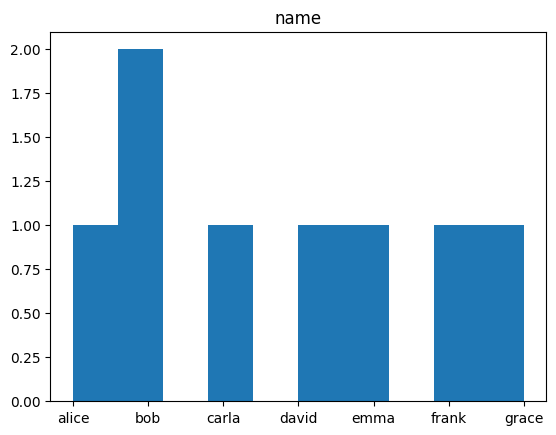

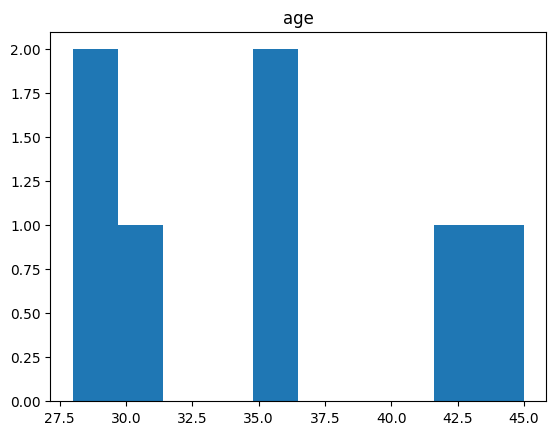

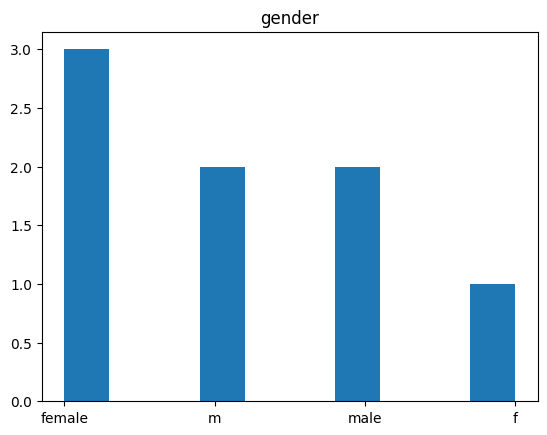

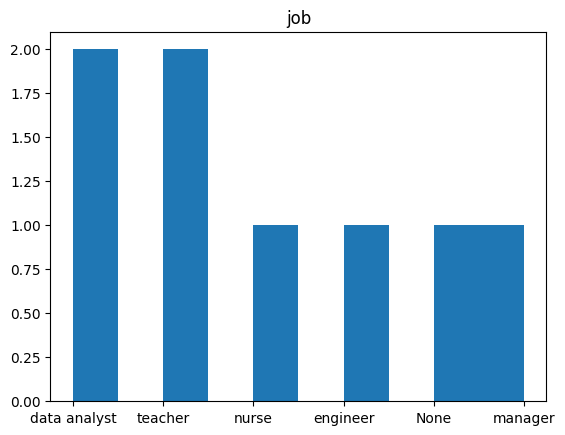

In [169]:
#examin the data
for i in df.columns:
  plt.figure()
  plt.title(i)
  plt.hist(df[i])

We can see that we need to encode the gender feature. Since we're going to transform into a binary fiels anyway, we can do so at the same time

In [170]:
# Map gender values to a 0 or 1, 0 for male and 1 for female
df['gender'] = df['gender'].map({'male': 0, 'm': 0, 'female': 1, 'f': 1})
df

,name,age,gender,job
0,alice,28.0,1,data analyst
1,bob,35.0,0,teacher
2,carla,42.0,1,nurse
3,david,NaN,0,engineer
4,emma,31.0,1,data analyst
5,frank,29.0,0,None
6,grace,45.0,1,manager
7,bob,35.0,0,teacher


In [171]:
#Based on the age histogram we can reasonably impute the missing age values based on the mean of available ages
df['age'] = df['age'].fillna(df['age'].mean())
df

,name,age,gender,job
0,alice,28.0,1,data analyst
1,bob,35.0,0,teacher
2,carla,42.0,1,nurse
3,david,35.0,0,engineer
4,emma,31.0,1,data analyst
5,frank,29.0,0,None
6,grace,45.0,1,manager
7,bob,35.0,0,teacher


In [172]:
# We will now count and remove duplicate records
df.duplicated().sum()

np.int64(1)

In [173]:
df = df.drop_duplicates()
print(f"{df.duplicated().sum()} duplicates")
df

0 duplicates


,name,age,gender,job
0,alice,28.0,1,data analyst
1,bob,35.0,0,teacher
2,carla,42.0,1,nurse
3,david,35.0,0,engineer
4,emma,31.0,1,data analyst
5,frank,29.0,0,None
6,grace,45.0,1,manager


In [174]:
# Now we will one hot encode the jobs fields
df = pd.get_dummies(df, columns=['job'])
df

,name,age,gender,job_None,job_data analyst,job_engineer,job_manager,job_nurse,job_teacher
0,alice,28.0,1,False,True,False,False,False,False
1,bob,35.0,0,False,False,False,False,False,True
2,carla,42.0,1,False,False,False,False,True,False
3,david,35.0,0,False,False,True,False,False,False
4,emma,31.0,1,False,True,False,False,False,False
5,frank,29.0,0,True,False,False,False,False,False
6,grace,45.0,1,False,False,False,True,False,False


<Axes: >

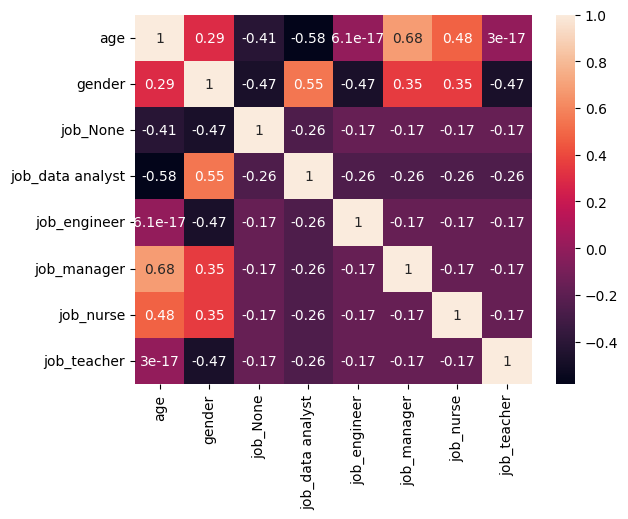

In [191]:
df_slice = df.iloc[:, 1:]

sns.heatmap(df_slice.corr(), annot=True)